# PHYS 311: Block 2 Checkpoint
## Multi-Body Physics Engine Demonstration

This checkpoiny demonstrates the capabilities of the Python physics engine that was developed in Lab 7. The simulation includes four interacting bodies, mulitple forces, and elastic collisions.

The results will be evaluated using conservation of energy and momentum to verify if the engine is numerically accurate.

# Part A: Engine Setup and Initial Conditions

In [76]:
## Imports

import numpy as np
import matplotlib.pyplot as plt

from block2_engine import (
    Body,
    World,
    Gravity,
    Spring,
    CircleCollisions,
    EulerCromer
)

print("Block 2 engine imported successfully!")

Block 2 engine imported successfully!


## Part A.1: Initial Conditions

Four circular bodies are initialized with equal masses and radii. Each body has an initial position and velocity across the two-dimensional space.

The bodies will interact through spring forces and elastic collisions. Additionally, uniform gravity will act on the system.

In [77]:
# PART A.1: INITIAL CONDITIONS

# Physical parameters
mass = 1.0          # kg
radius = 0.20       # m
g = 9.81            # m/s^2
k = 10.0            # N/m
L0 = 1.0            # m

# Simulation parameters
dt = 0.001          # seconds
t_end = 5.0         # seconds

# Define four interacting bodies
bodies = [
    Body(m=mass, r=(-1.0, 2.0), v=( 0.5, 0.0),
         radius=radius, name="A"),

    Body(m=mass, r=( 1.0, 2.0), v=(-0.5, 0.0),
         radius=radius, name="B"),

    Body(m=mass, r=(-1.0, 3.5), v=( 0.5, 0.0),
         radius=radius, name="C"),

    Body(m=mass, r=( 1.0, 3.5), v=(-0.5, 0.0),
         radius=radius, name="D")
]

print("Number of bodies:", len(bodies))

for body in bodies:
    print(body)

Number of bodies: 4
Body(A, m=1.0, r=[-1.  2.], v=[0.5 0. ])
Body(B, m=1.0, r=[1. 2.], v=[-0.5  0. ])
Body(C, m=1.0, r=[-1.   3.5], v=[0.5 0. ])
Body(D, m=1.0, r=[1.  3.5], v=[-0.5  0. ])


## A.2: Forces and Collision Interactions

The simulation utilizes two distinct types of forces:

1. Uniform gravitational force acting downward to all bodies.
2. Spring forces connecting pairs of bodies according to Hooke's law.

Collisions between the circular bodies are modeled as perfectly elastic, with a coefficient of resitution equal to 1.0.

In [78]:
# PART A.2: FORCES AND COLLISIONS

# Gravity and spring forces
forces = [
    Gravity(g=g),

    Spring(0, 1, k=k, L0=L0),
    Spring(2, 3, k=k, L0=L0),
    Spring(0, 2, k=k, L0=L0),
    Spring(1, 3, k=k, L0=L0)
]

# Elastic body-to-body collisions
collisions = CircleCollisions(e=1.0)

# Construct the simulation world
world = World(
    bodies=bodies,
    forces=forces,
    constraints=[collisions],
    integrator=EulerCromer()
)

print("Simulation world initialized.")
print("Number of bodies:", len(world.bodies))
print("Number of forces:", len(world.forces))
print("Integrator:", world.integrator.name)


Simulation world initialized.
Number of bodies: 4
Number of forces: 5
Integrator: Euler-Cromer


## A.3: Initial Energy and Momentum

The initial kinetic energy, potential energy, total mechanical energy, and linear momentum are calculated using the engine's built-in methods.

Naturally, these values provide a general reference for evaluating numerical conservation throughout the simulation.

In [79]:
# PART A.3: INITIAL DIAGNOSTICS

KE_initial = world.kinetic_energy()
PE_initial = world.potential_energy()
E_initial = world.total_energy()
P_initial = world.momentum()

print("INITIAL SYSTEM DIAGNOSTICS")
print("-" * 45)

print(f"Kinetic energy:   {KE_initial:.6f} J")
print(f"Potential energy: {PE_initial:.6f} J")
print(f"Total energy:     {E_initial:.6f} J")

print(f"Momentum Px:      {P_initial[0]:.6f} kg m/s")
print(f"Momentum Py:      {P_initial[1]:.6f} kg m/s")


INITIAL SYSTEM DIAGNOSTICS
---------------------------------------------
Kinetic energy:   0.500000 J
Potential energy: 120.410000 J
Total energy:     120.910000 J
Momentum Px:      0.000000 kg m/s
Momentum Py:      0.000000 kg m/s


# Part B: Multi-Body Simulation

## B.1: Simulation and Data Collection

The four-body system is simulated using the Euler-Cromer integration method with a fixed timestep of 0.001 seconds.

During the simulation, the positions of all four bodies, kinetic energy, potential energy, total mechanical energy, linear momentum, and collision counts are recorded.

These results will be utilized to visualize the motion and evaluate conservation laws.

In [80]:
# PART B.1: SIMULATION AND DATA RECORDING

# Storage arrays
times = [world.t]
positions = [[b.r.copy() for b in world.bodies]]

kinetic = [world.kinetic_energy()]
potential = [world.potential_energy()]
total_energy = [world.total_energy()]
momentum = [world.momentum().copy()]
collision_counts = [collisions.count]

# Run the simulation
n_steps = int(round(t_end / dt))

for step in range(n_steps):
    world.step(dt)

    times.append(world.t)
    positions.append([b.r.copy() for b in world.bodies])

    kinetic.append(world.kinetic_energy())
    potential.append(world.potential_energy())
    total_energy.append(world.total_energy())
    momentum.append(world.momentum().copy())
    collision_counts.append(collisions.count)

# Convert data into NumPy arrays
times = np.array(times)
positions = np.array(positions)

kinetic = np.array(kinetic)
potential = np.array(potential)
total_energy = np.array(total_energy)
momentum = np.array(momentum)
collision_counts = np.array(collision_counts)

print("SIMULATION COMPLETE")
print("-" * 45)
print(f"Simulation time:  {world.t:.3f} s")
print(f"Number of steps:  {n_steps}")
print(f"Bodies simulated: {len(world.bodies)}")
print(f"Total collisions: {collisions.count}")

SIMULATION COMPLETE
---------------------------------------------
Simulation time:  5.000 s
Number of steps:  5000
Bodies simulated: 4
Total collisions: 10


## B.2: Multi-Body Trajectories

The trajectories of all four bodies are plotted in two-dimensional space. Each trajectory shows how the body moves under the combined effects of gravity, spring forces, and elastic collisions.

The initial and final positions are then identified to illustrate the evolution of the system.

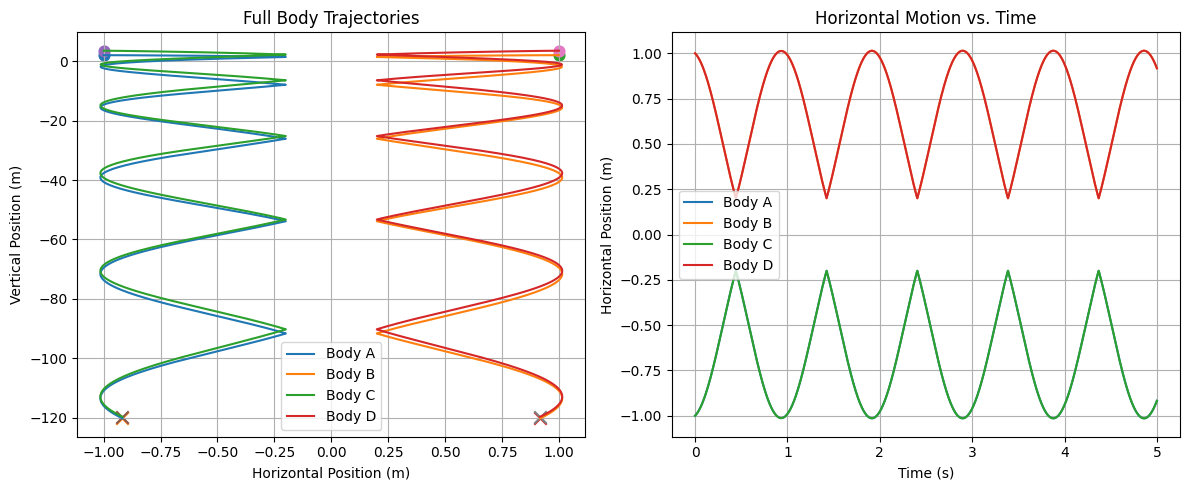

In [81]:
# PART B.2: TRAJECTORY VISUALIZATION

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel 1: Full trajectories
ax = axes[0]

for i, body in enumerate(world.bodies):
    x = positions[:, i, 0]
    y = positions[:, i, 1]

    ax.plot(x, y, label=f"Body {body.name}")
    ax.scatter(x[0], y[0], marker="o", s=60)
    ax.scatter(x[-1], y[-1], marker="x", s=80)

ax.set_title("Full Body Trajectories")
ax.set_xlabel("Horizontal Position (m)")
ax.set_ylabel("Vertical Position (m)")
ax.grid(True)
ax.legend()

# Panel 2: Horizontal motion over time
ax = axes[1]

for i, body in enumerate(world.bodies):
    ax.plot(
        times,
        positions[:, i, 0],
        label=f"Body {body.name}"
    )

ax.set_title("Horizontal Motion vs. Time")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Horizontal Position (m)")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

## B.3: Collision Verification

The engine's collision counter is used to determine whether any collisions occured during the simulation.

The cumulative collision count is pplotted against time to demonstrate that the collision detection and resolution components were actively utilized.

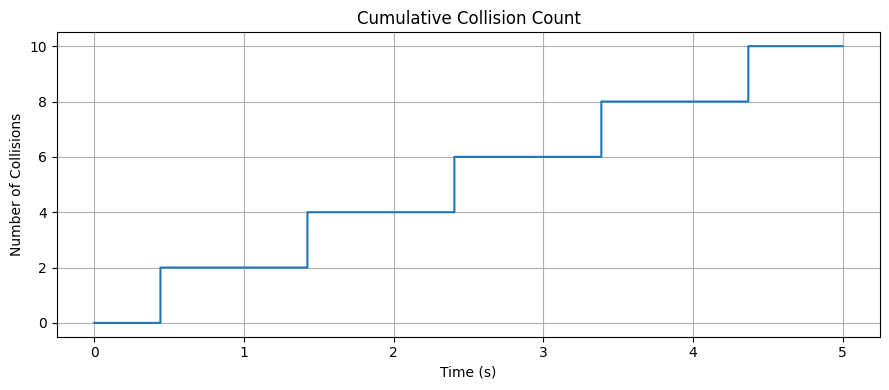

COLLISION VERIFICATION
---------------------------------------------
Total collisions detected: 10
PASS: At least one collision occurred.


In [82]:
# PART B.3: COLLISION VERIFICATION

fig, ax = plt.subplots(figsize=(9, 4))

ax.step(times, collision_counts, where="post")

ax.set_title("Cumulative Collision Count")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Number of Collisions")

ax.grid(True)

plt.tight_layout()
plt.show()

print("COLLISION VERIFICATION")
print("-" * 45)

print(f"Total collisions detected: {collisions.count}")

if collisions.count > 0:
    print("PASS: At least one collision occurred.")
else:
    print("FAIL: No collisions occurred.")
    print("Initial conditions must be adjusted.")

## B.4: Simulation Verification

The simulation results are checked for invalid numerical values, the correct number of bodies, and successful collision detection.

These checks help confirm that the recorded data is overall suitable for conservatin-law analysis. (This was mostly an intermediate step).

In [83]:
# PART B.4: SIMULATION VERIFICATION

print("SIMULATION VERIFICATION")
print("-" * 45)

# Check body count
print(f"Four bodies:     {'PASS' if len(world.bodies) == 4 else 'FAIL'}")

# Check numerical values
valid_positions = np.all(np.isfinite(positions))
valid_energy = np.all(np.isfinite(total_energy))
valid_momentum = np.all(np.isfinite(momentum))

print(f"Valid positions: {'PASS' if valid_positions else 'FAIL'}")
print(f"Valid energy:    {'PASS' if valid_energy else 'FAIL'}")
print(f"Valid momentum:  {'PASS' if valid_momentum else 'FAIL'}")

# Check collisions
print(f"Collision test:  {'PASS' if collisions.count > 0 else 'FAIL'}")

# Check time
print(f"Final time:      {world.t:.3f} s")

SIMULATION VERIFICATION
---------------------------------------------
Four bodies:     PASS
Valid positions: PASS
Valid energy:    PASS
Valid momentum:  PASS
Collision test:  PASS
Final time:      5.000 s


## Part B: Analysis

The four-body simulation successfully demonstrated the combined effects of gravity, spring forces, and elastic collisions. All four bodies accelerated downward under gravity while oscillating horizontally due to the spring interactions.

The simulation detected 10 collisions over the five-second interval, confirming that the collision detection and resolution components are functioning. All recorded values remained valid, which demonstrates that the engine can handle multiple interacting bodies throughout the simulation!

# Part C: Conservation-Law Validation

## C.1: Energy Conservation

The simulation's kinetic, potential, and total mechanical energies are evaluated over time.

Because gravity and spring forces are conservative and collisions are modeled as perfectly elastic, the total mechanical energy should remain approximately constant throughout the simulation.

Small deviations are generally expected due to numerical integration and collision resolution.

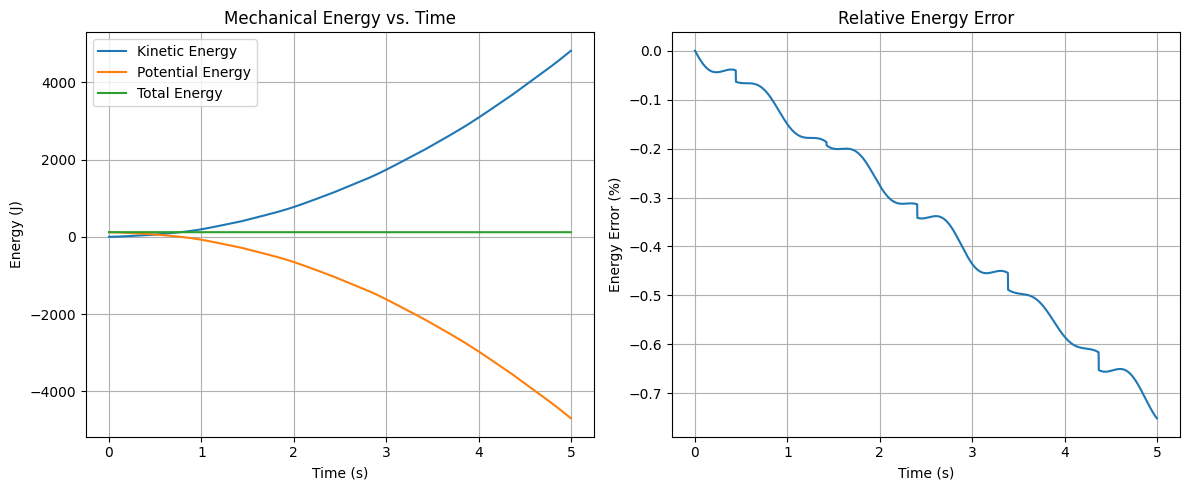

ENERGY CONSERVATION RESULTS
---------------------------------------------
Initial energy:       120.910000 J
Final energy:         120.001634 J
Maximum energy error: 0.751275%


In [84]:
# PART C.1: ENERGY CONSERVATION

# Calculate energy deviation
E0 = total_energy[0]

energy_error = (
    (total_energy - E0) / abs(E0)
) * 100

max_energy_error = np.max(np.abs(energy_error))

# Plot energy components and numerical error
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel 1: Energy components
ax = axes[0]

ax.plot(times, kinetic, label="Kinetic Energy")
ax.plot(times, potential, label="Potential Energy")
ax.plot(times, total_energy, label="Total Energy")

ax.set_title("Mechanical Energy vs. Time")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Energy (J)")
ax.grid(True)
ax.legend()

# Panel 2: Relative energy error
ax = axes[1]

ax.plot(times, energy_error)

ax.set_title("Relative Energy Error")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Energy Error (%)")
ax.grid(True)

plt.tight_layout()
plt.show()

print("ENERGY CONSERVATION RESULTS")
print("-" * 45)
print(f"Initial energy:       {E0:.6f} J")
print(f"Final energy:         {total_energy[-1]:.6f} J")
print(f"Maximum energy error: {max_energy_error:.6f}%")

## C.2: Momentum Conservation

Horizontal and vertical momentum are evaluated throughout the simulation.

Horizontal momentum should remain constant as there are no external horizontal forces acting on the system. Vertical momentum is expected to change because of gravity.

The results will be compared against what is physically expected.

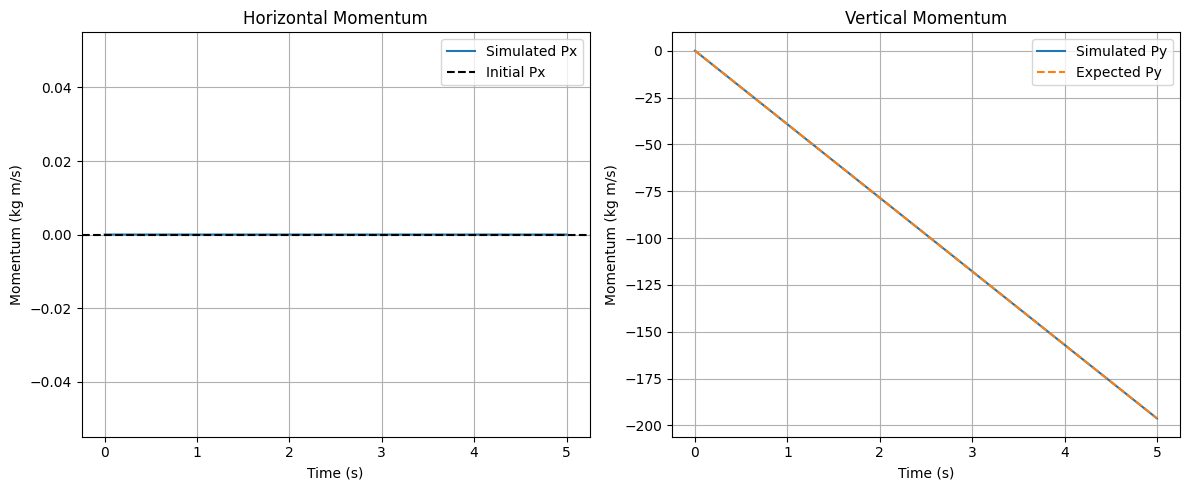

MOMENTUM CONSERVATION RESULTS
---------------------------------------------
Initial Px:           0.00000000 kg m/s
Final Px:             0.00000000 kg m/s
Maximum Px deviation: 0.00000000e+00 kg m/s
Initial Py:           0.000000 kg m/s
Final Py:             -196.200000 kg m/s
Expected final Py:    -196.200000 kg m/s


In [85]:
# PART C.2: MOMENTUM CONSERVATION

Px = momentum[:, 0]
Py = momentum[:, 1]

Px0 = Px[0]
Py0 = Py[0]

# Expected vertical momentum under gravity
total_mass = sum(b.m for b in world.bodies)
Py_expected = Py0 - total_mass * g * times

# Calculate horizontal momentum error
Px_error = Px - Px0
max_Px_error = np.max(np.abs(Px_error))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel 1: Horizontal momentum
ax = axes[0]

ax.plot(times, Px, label="Simulated Px")
ax.axhline(Px0, linestyle="--", color="black",
           label="Initial Px")

ax.set_title("Horizontal Momentum")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Momentum (kg m/s)")
ax.grid(True)
ax.legend()

# Panel 2: Vertical momentum
ax = axes[1]

ax.plot(times, Py, label="Simulated Py")
ax.plot(times, Py_expected, "--", label="Expected Py")

ax.set_title("Vertical Momentum")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Momentum (kg m/s)")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

print("MOMENTUM CONSERVATION RESULTS")
print("-" * 45)

print(f"Initial Px:           {Px0:.8f} kg m/s")
print(f"Final Px:             {Px[-1]:.8f} kg m/s")
print(f"Maximum Px deviation: {max_Px_error:.8e} kg m/s")

print(f"Initial Py:           {Py0:.6f} kg m/s")
print(f"Final Py:             {Py[-1]:.6f} kg m/s")
print(f"Expected final Py:    {Py_expected[-1]:.6f} kg m/s")

## C.3: Conservation Summary

The simulation is evaluated using the maximum relative energy error, horizontal momentum deviation, and number of detected collisions.

These measurements help to provide an assessment of the physics engine's behavior.

In [86]:
# PART C.3: CONSERVATION SUMMARY

print("BLOCK 2 CHECKPOINT: VALIDATION SUMMARY")
print("=" * 50)

print(f"Number of bodies:           {len(world.bodies)}")
print(f"Force types:                Gravity and Spring")
print(f"Collision model:            Elastic (e = 1.0)")
print(f"Total collisions:           {collisions.count}")
print(f"Integration method:         {world.integrator.name}")

print("-" * 50)

print(f"Maximum energy error:       {max_energy_error:.6f}%")
print(f"Maximum Px deviation:       {max_Px_error:.8e} kg m/s")
print(f"Final Py prediction error:  {abs(Py[-1] - Py_expected[-1]):.8e} kg m/s")

print("=" * 50)

BLOCK 2 CHECKPOINT: VALIDATION SUMMARY
Number of bodies:           4
Force types:                Gravity and Spring
Collision model:            Elastic (e = 1.0)
Total collisions:           10
Integration method:         Euler-Cromer
--------------------------------------------------
Maximum energy error:       0.751275%
Maximum Px deviation:       0.00000000e+00 kg m/s
Final Py prediction error:  0.00000000e+00 kg m/s


## Part C: Analysis

The simulation demonstrated reasonable conservation of mechanical energy, with an initial energy of 120.910 J and a final energy of 120.002 J. The maximum relative energy error was approximately 0.751%, which is likely resulting from numerical integration and collision resolution.

Horizontal momentum remained constant at 0 kg m/s, with no measurable deviation, which is consistent with the absence of external horizontal forces. Vertical momentum decreased to -196.2 kg m/s, matching the theoretical prediction under gravity.

Overall, the results support the accuracy of the engine's force calculations, collision handling, and numerical integration, with relatively small energy deviations despite the 10 elastic collisions.

# Part D: Engine Demonstration

## D.1: Multi-Panel Simulation Summary

The following figure summarizes the four-body physics simulation, including body trajectories, horizontal motion, mechanical energy conservation, and collision interactions.

The simulation uses gravity, spring forces, and elastic collisions to demonstrate the engine's ability to handle multiple interacting bodies while maintaining reasonable numerical accuracy.

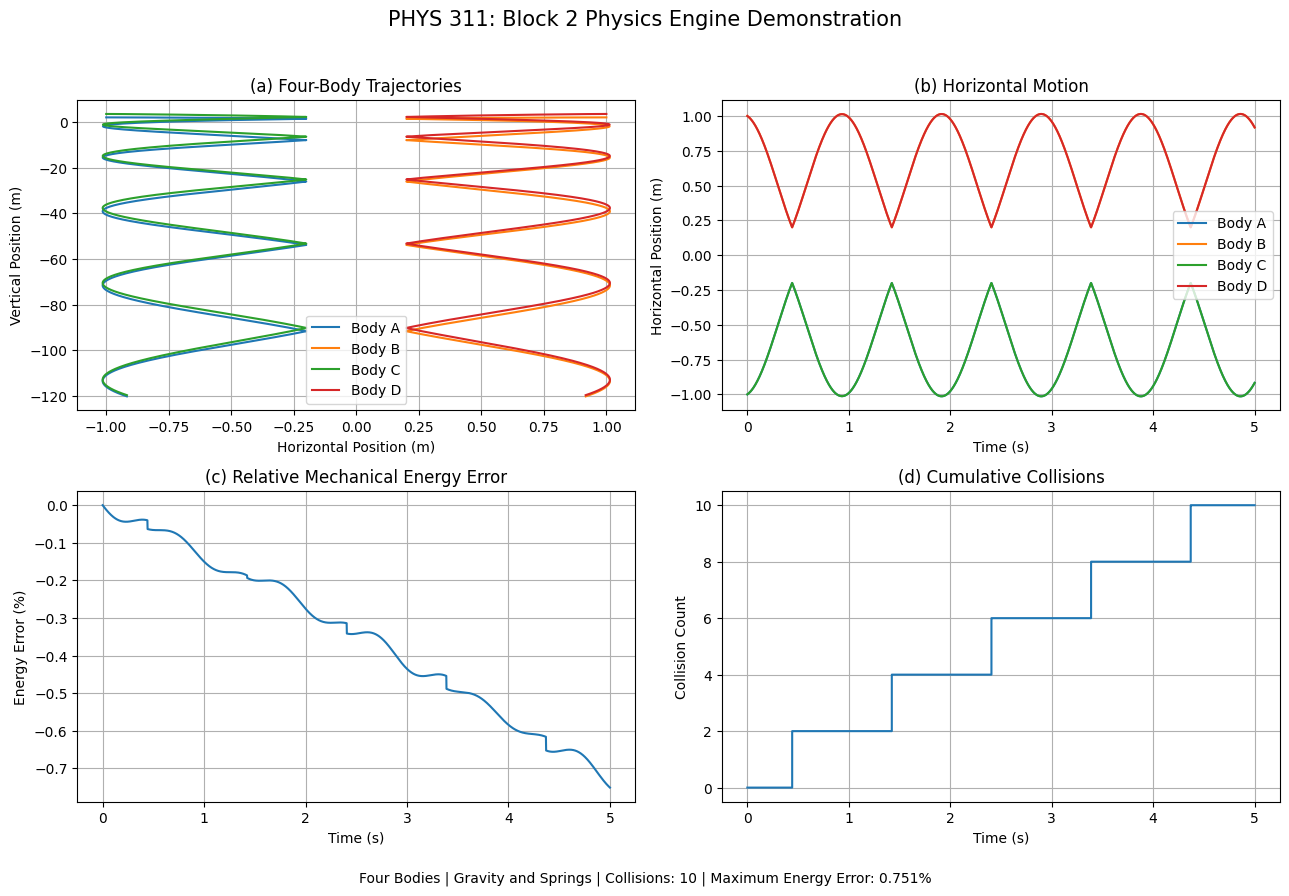

Summary figure saved successfully.


In [87]:
# PART D.1: MULTI-PANEL ENGINE DEMONSTRATION

from pathlib import Path

# Create output folder
output_dir = Path("figures")
output_dir.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Panel 1: Body trajectories
ax = axes[0, 0]

for i, body in enumerate(world.bodies):
    ax.plot(
        positions[:, i, 0],
        positions[:, i, 1],
        label=f"Body {body.name}"
    )

ax.set_title("(a) Four-Body Trajectories")
ax.set_xlabel("Horizontal Position (m)")
ax.set_ylabel("Vertical Position (m)")
ax.grid(True)
ax.legend()

# Panel 2: Horizontal motion
ax = axes[0, 1]

for i, body in enumerate(world.bodies):
    ax.plot(
        times,
        positions[:, i, 0],
        label=f"Body {body.name}"
    )

ax.set_title("(b) Horizontal Motion")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Horizontal Position (m)")
ax.grid(True)
ax.legend()

# Panel 3: Energy conservation
ax = axes[1, 0]

ax.plot(times, energy_error)

ax.set_title("(c) Relative Mechanical Energy Error")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Energy Error (%)")
ax.grid(True)

# Panel 4: Collision count
ax = axes[1, 1]

ax.step(times, collision_counts, where="post")

ax.set_title("(d) Cumulative Collisions")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Collision Count")
ax.grid(True)

fig.suptitle(
    "PHYS 311: Block 2 Physics Engine Demonstration",
    fontsize=15
)

fig.text(
    0.5, 0.01,
    f"Four Bodies | Gravity and Springs | "
    f"Collisions: {collisions.count} | "
    f"Maximum Energy Error: {max_energy_error:.3f}%",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.035, 1, 0.96])

fig.savefig(
    output_dir / "block2_summary.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Summary figure saved successfully.")

## D.2: Multi-Frame Simulation Snapshots

Six snapshots are generated to illustrate the evolution of the four-body system over the simulation interval.

Each panel displays the positions of all four bodies and their spring connections at a different time. These snapshots simply provide a visual representation of the changing configuration of the system as gravity, spring forces, and collisions influence its motion.

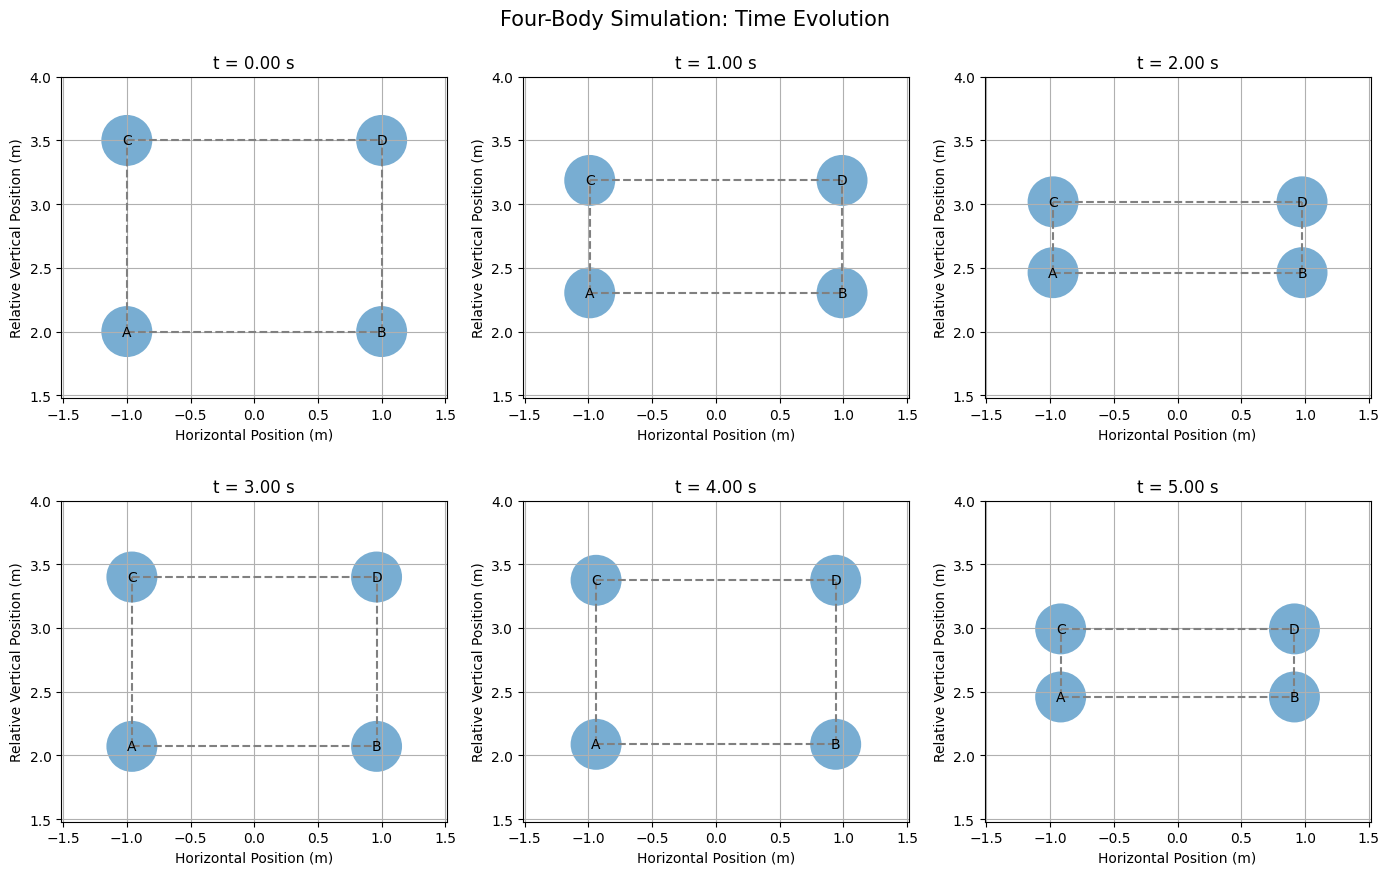

Simulation snapshots saved successfully.


In [88]:
# PART D.2: MULTI-FRAME SIMULATION SNAPSHOTS

from matplotlib.patches import Circle

# Select six equally spaced simulation times
snapshot_times = np.linspace(0, t_end, 6)

# Spring connections, matching Part A
spring_pairs = [
    (0, 1),
    (2, 3),
    (0, 2),
    (1, 3)
]

# Set common horizontal bounds
xmin = np.min(positions[:, :, 0]) - 0.5
xmax = np.max(positions[:, :, 0]) + 0.5

# Use a falling reference frame to make the interactions visible
# This removes the common gravitational displacement.
relative_positions = positions.copy()
relative_positions[:, :, 1] += 0.5 * g * times[:, None]**2

ymin = np.min(relative_positions[:, :, 1]) - 0.5
ymax = np.max(relative_positions[:, :, 1]) + 0.5

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, snapshot_time in zip(axes.flat, snapshot_times):

    idx = np.argmin(np.abs(times - snapshot_time))

    frame = relative_positions[idx]

    # Draw spring connections
    for i, j in spring_pairs:
        ax.plot(
            [frame[i, 0], frame[j, 0]],
            [frame[i, 1], frame[j, 1]],
            color="gray",
            linestyle="--",
            linewidth=1.5
        )

    # Draw the four bodies
    for i, body in enumerate(world.bodies):

        x, y = frame[i]

        circle = Circle(
            (x, y),
            body.radius,
            alpha=0.6
        )

        ax.add_patch(circle)

        ax.text(
            x, y,
            body.name,
            ha="center",
            va="center",
            fontsize=10
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"t = {times[idx]:.2f} s")

    ax.set_xlabel("Horizontal Position (m)")
    ax.set_ylabel("Relative Vertical Position (m)")

    ax.grid(True)

fig.suptitle(
    "Four-Body Simulation: Time Evolution",
    fontsize=15
)

plt.tight_layout()

fig.savefig(
    output_dir / "block2_snapshots.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Simulation snapshots saved successfully.")

## Part D: Analysis

The multi-panel figures demonstrate the behavior of the four-body system under gravity, spring forces, and elastic collisions. The trajectories show all four bodies accelerating downward while oscillating horizontally. The time-evolution snapshots, displayed in a freely falling reference frame, illustrate the changing spring configurations and relative positions of the bodies.

The simulation detected 10 elastic collisions over five seconds, confirming that the collision resolution system was actively used. The mechanical energy error gradually increased throughout the simulation, reaching a maximum of approximately 0.751%. Small changes in the energy error near collision events suggest that collision resolution contributes to the numerical deviations.

Overall, the results demonstrate that the engine is able to successfully handle multiple interacting bodies while maintaining reasonable energy conservation. The combination of trajectory plots, collision tracking, and conservation measurements provides evidence of the engine's functionality and numerical accuracy.